# Decisions over a scientific record: functions, branches and loops

Which recorded temperatures meet a declared rule, and how do missing values affect the answer?

Winter 2026.


# A declared rule over a record
Predict the category of None, 40 and 40.1 at target 40. The following small function is a guided example; extend its tests before using the supplied validated analyzer.

In [1]:
def classify_simple(value, target):
    if value is None:
        return "missing"
    if value <= target:
        return "at_or_below"
    return "above"

for value in [None, 40, 40.1]:
    print(value, classify_simple(value, 40))

None missing
40 at_or_below
40.1 above


Trace the first three iterations by hand. Then run the loop and explain what each counter and the first-time sentinel mean.

In [2]:
times = [0, 1, 2, 3, 4, 5, 6, 7, 8]
readings = [80, 62, 48, 40, 35, None, 28, 25, 23]
target = 40
counts = {"above": 0, "at_or_below": 0, "missing": 0}
first_time = None
for time, value in zip(times, readings):
    category = classify_simple(value, target)
    counts[category] += 1
    if category == "at_or_below" and first_time is None:
        first_time = time
print(counts, "first recorded time (min):", first_time)
assert sum(counts.values()) == len(readings)

{'above': 3, 'at_or_below': 5, 'missing': 1} first recorded time (min): 3


Now run the supplied validated analyzer and display its baseline figures. Interpret the missing gap and the step curve. The target is a teaching parameter, not a safety limit.

{'target_C': 40.0, 'counts': {'above': 3, 'at_or_below': 5, 'missing': 1}, 'known_readings': 8, 'fraction_of_known_at_or_below': 0.625, 'first_recorded_time_min': 3.0, 'states': ['above', 'above', 'above', 'at_or_below', 'at_or_below', 'missing', 'at_or_below', 'at_or_below', 'at_or_below'], 'checks': {'equality_included': True, 'all_missing_fraction_is_None': True, 'zero_first_time_preserved': True, 'invalid_inputs_rejected': 4}}


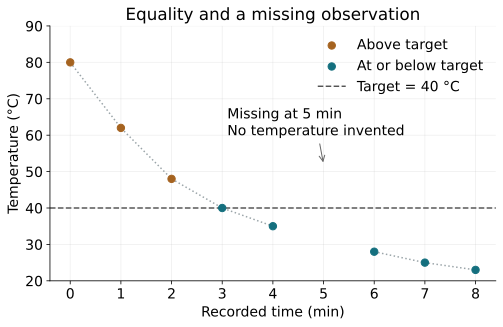

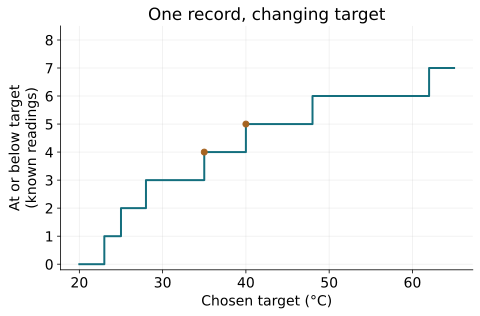

In [3]:
from demo import run, analyze
from IPython.display import SVG, display
report = run()
print(report)
display(SVG(filename="threshold-record.svg"))
display(SVG(filename="threshold-counts.svg"))

Predict how the qualifying count changes if the target becomes 35, then run the cell. Next choose another target yourself. Explain which denominator stays fixed. Finally restart and run all cells.

In [4]:
changed_target = 35
changed = analyze(times, readings, changed_target)
print("Changed target (degrees C):", changed_target)
print(changed)
print("All missing:", analyze([0, 1], [None, None], changed_target))
print("First time zero:", analyze([0, 1], [35, 34], changed_target))

Changed target (degrees C): 35
{'target_C': 35, 'counts': {'above': 4, 'at_or_below': 4, 'missing': 1}, 'known_readings': 8, 'fraction_of_known_at_or_below': 0.5, 'first_recorded_time_min': 4, 'states': ['above', 'above', 'above', 'above', 'at_or_below', 'missing', 'at_or_below', 'at_or_below', 'at_or_below']}
All missing: {'target_C': 35, 'counts': {'above': 0, 'at_or_below': 0, 'missing': 2}, 'known_readings': 0, 'fraction_of_known_at_or_below': None, 'first_recorded_time_min': None, 'states': ['missing', 'missing']}
First time zero: {'target_C': 35, 'counts': {'above': 0, 'at_or_below': 2, 'missing': 0}, 'known_readings': 2, 'fraction_of_known_at_or_below': 1.0, 'first_recorded_time_min': 0, 'states': ['at_or_below', 'at_or_below']}


Write one sentence reporting your changed rule, known-reading fraction and first recorded time. State why that time does not determine an exact continuous crossing. The separate exercises use new inputs; do not treat this demonstration as their answer key.